# Activité Pratique N°4 — Architecture Transformer

**Module :** IA Générative Multi-Modale — Pr. Youssfi

**Travail à faire**

*Première partie*
1. Générer une série temporelle $y = \sin(x)$ (200 valeurs entre 0 et 20) et la ranger en séquences de 10 éléments.
2. Créer, entraîner et tester un modèle **RNN** qui prédit la valeur suivante d'une séquence de 10 éléments.
3. Faire de même avec un modèle **LSTM**.
4. Faire de même avec un **Transformer** (encodeur).
5. Créer et tester un modèle de type **GPT** : prédire la suite d'un texte.
6. Créer et tester un modèle de type **BERT** : prédire un mot masqué dans une séquence.

*Deuxième partie* : Exercices 1, 2 et 3 (fin du notebook).

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch :", torch.__version__)

# Dictionnaire pour comparer les trois modèles à la fin de la partie 1
resultats = {}

PyTorch : 2.15.0


---
# Partie 1

## 1. Génération du dataset : série temporelle $s = \sin(x)$

On prend **200 valeurs** de $x$ régulièrement espacées entre 0 et 20, puis $s_t = \sin(x_t)$.

Le dataset est rangé sous forme de **fenêtres glissantes de dimension 10** :

$$
X = \big[[s_0, \dots, s_9],\ [s_1, \dots, s_{10}],\ [s_2, \dots, s_{11}],\ \dots\big]
\qquad
Y = \big[s_{10},\ s_{11},\ s_{12},\ \dots\big]
$$

On obtient $200 - 10 = 190$ exemples. Le découpage est **chronologique** : les 150 premiers pour l'entraînement, les 40 derniers pour le test.

In [2]:
torch.manual_seed(42)

# --------------------------------------------------
# Créer la série temporelle
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)   # 200 valeurs de x entre 0 et 20
serie = torch.sin(periode)             # s = sin(x)
longueur_sequence = 10

# Chaque entrée contient 10 valeurs, la cible est la valeur suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Format attendu par les modèles : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X       :", tuple(X.shape), "| y      :", tuple(y.shape))
print("X_train :", tuple(X_train.shape), "| y_train:", tuple(y_train.shape))
print("X_test  :", tuple(X_test.shape), " | y_test :", tuple(y_test.shape))
print("\nPremière séquence :", [round(v, 3) for v in X[0, :, 0].tolist()])
print("Cible associée    :", round(y[0].item(), 3), "(= s10 =", round(serie[10].item(), 3), ")")

X       : (190, 10, 1) | y      : (190, 1)
X_train : (150, 10, 1) | y_train: (150, 1)
X_test  : (40, 10, 1)  | y_test : (40, 1)

Première séquence : [0.0, 0.1, 0.2, 0.297, 0.391, 0.482, 0.567, 0.647, 0.72, 0.786]
Cible associée    : 0.844 (= s10 = 0.844 )


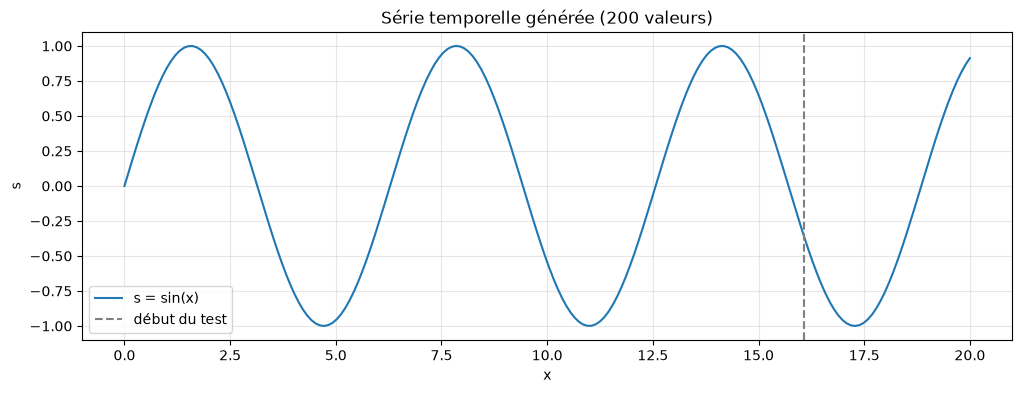

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(periode, serie, label="s = sin(x)")
# Frontière entre entraînement et test (cible du 1er exemple de test = indice 160)
plt.axvline(periode[150 + longueur_sequence], color="gray", linestyle="--", label="début du test")
plt.xlabel("x")
plt.ylabel("s")
plt.title("Série temporelle générée (200 valeurs)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Les trois modèles (RNN, LSTM, Transformer) sont entraînés et testés **exactement de la même manière** (MSE, Adam `lr=0.01`, 300 époques, un lot contenant les 150 séquences). On regroupe donc cette boucle dans deux fonctions pour ne pas la répéter.

In [4]:
def entrainer(modele, X_train, y_train, epochs=300, lr=0.01):
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    modele.train()
    for epoch in range(epochs):
        predictions = modele(X_train)          # propagation avant
        perte = critere(predictions, y_train)  # erreur quadratique moyenne

        optimiseur.zero_grad()  # effacer les anciens gradients
        perte.backward()        # calculer les nouveaux gradients
        optimiseur.step()       # mettre à jour les paramètres

        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


def tester(modele, X_test, y_test, nom):
    critere = nn.MSELoss()
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_test)
        erreur_test = critere(predictions, y_test).item()
    print(f"\nErreur de test (MSE) : {erreur_test:.6f}")
    print(f"Valeur réelle  : {y_test[0].item():.4f}")
    print(f"Valeur prédite : {predictions[0].item():.4f}")

    plt.figure(figsize=(12, 4))
    plt.plot(y_test.reshape(-1).numpy(), label="Valeurs réelles", color="blue", linewidth=2)
    plt.plot(predictions.reshape(-1).numpy(), label=f"Prédictions du {nom}",
             color="red", linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions (jeu de test)")
    plt.xlabel("Indice de l'échantillon de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    return erreur_test, predictions


def nb_parametres(modele):
    return sum(p.numel() for p in modele.parameters())

---
## 2. Modèle RNN

Un **RNN** lit la séquence élément par élément et met à jour un état caché (sa mémoire) :

$$
h_t = \tanh(W_{ih}x_t + W_{hh}h_{t-1} + b)
$$

Les mêmes poids sont réutilisés à chaque instant. L'architecture (tableau) :

```
h0 = 0 → [RNN 16 unités] → h1 → [RNN 16 unités] → h2 → … → [RNN 16 unités] → h10 → Linear(16→1) → ŷ
            ↑ x1                    ↑ x2                       ↑ x10
```

Dimensions : $(B, 10, 1) \xrightarrow{\text{RNN}} (B, 10, 16) \xrightarrow{\text{dernier état}} (B, 16) \xrightarrow{\text{Linear}} (B, 1)$

In [5]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(
            input_size=1,     # une valeur à chaque instant
            hidden_size=16,   # une mémoire de 16 nombres
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # h0 = 0 par défaut
        etats, _ = self.rnn(x)            # (B, 10, 16)
        dernier_etat = etats[:, -1, :]    # (B, 16)
        return self.sortie(dernier_etat)  # (B, 1)


torch.manual_seed(42)
modele_rnn = SimpleRNN()
print(modele_rnn)
print("Nombre de paramètres :", nb_parametres(modele_rnn))

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 321


### Entraînement et test du RNN

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test (MSE) : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


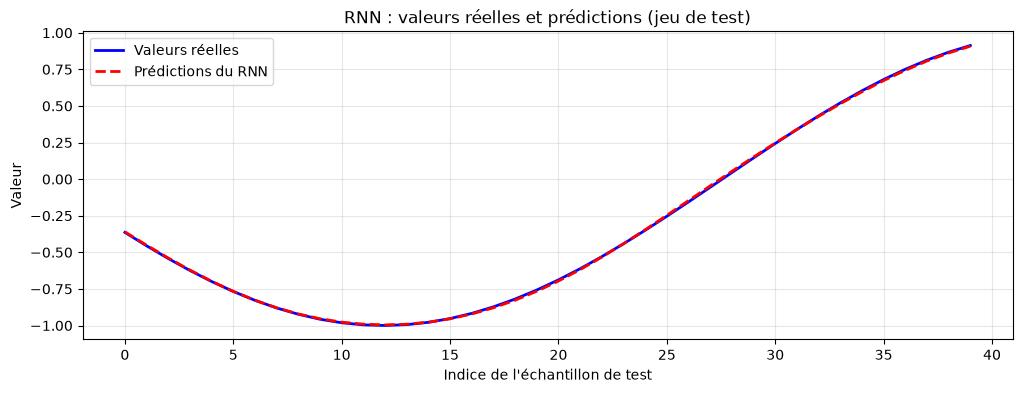

In [6]:
entrainer(modele_rnn, X_train, y_train)
resultats["RNN"], pred_rnn = tester(modele_rnn, X_test, y_test, "RNN")

---
## 3. Modèle LSTM

Le **LSTM** est une variante du RNN qui transmet **deux états** d'un instant au suivant : l'état caché $h_t$ et l'état de cellule $c_t$ (mémoire à long terme). Trois portes (oubli $f_t$, entrée $i_t$, sortie $o_t$) contrôlent l'information :

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t \qquad h_t = o_t \odot \tanh(c_t)
$$

```
c0 = 0 → [LSTM 16 unités, instant 1] → c1 → … → [LSTM 16 unités, instant n] → cn
h0 = 0 →                              → h1 → … →                             → hn → Linear(16→1) → ŷ
```

Même configuration que le RNN : `input_size=1`, `hidden_size=16`, 1 couche, sortie `Linear(16, 1)` appliquée au dernier état caché.

In [7]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1,     # une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # une seule couche LSTM
            batch_first=True
        )
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # h0 et c0 sont initialisés à zéro par défaut
        etats, (h_final, c_final) = self.lstm(x)  # etats : (B, 10, 16)
        dernier_etat = etats[:, -1, :]            # (B, 16)
        return self.sortie(dernier_etat)          # (B, 1)


torch.manual_seed(42)
modele_lstm = SimpleLSTM()
print(modele_lstm)
print("Nombre de paramètres :", nb_parametres(modele_lstm))

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 1233


### Entraînement et test du LSTM

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248


Epoch 150 | Erreur : 0.000043


Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004


Epoch 300 | Erreur : 0.000003

Erreur de test (MSE) : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


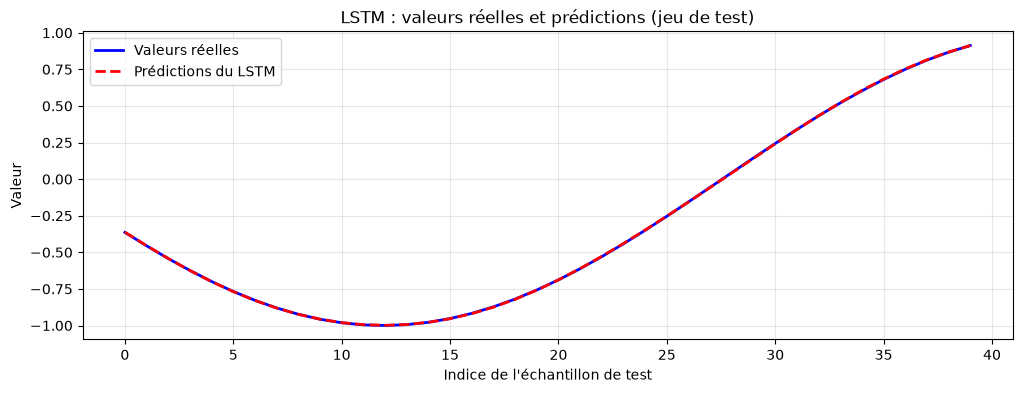

In [8]:
entrainer(modele_lstm, X_train, y_train)
resultats["LSTM"], pred_lstm = tester(modele_lstm, X_test, y_test, "LSTM")

---
## 4. Modèle Transformer

Le **Transformer** ne transmet pas de mémoire récurrente : il met directement en relation toutes les positions grâce à l'**auto-attention** :

$$
\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\left(\frac{QK^\top}{\sqrt{d_k}}\right)V
$$

Architecture (tableau) :

```
Entrées x1..x10 ──► Projection linéaire 1→16 ──┐
Indices 0..9    ──► Positional Embedding     ──┴─► (+)
                                                    │
                        Multi-Head Self-Attention (2 têtes, d_model=16)
                                                    │
                        Addition (résiduel) + Norm Layer
                                                    │
                        Feed Forward 16→32→16 avec ReLU
                                                    │
                        Addition (résiduel) + Norm Layer
                                                    │
                        Garder la dernière représentation [:, -1, :]
                                                    │
                                          Linear(16→1) ──► ŷ
```

Dimensions : $(B, 10, 1) \xrightarrow{\text{proj + pos}} (B, 10, 16) \xrightarrow{\text{encodeur}} (B, 10, 16) \xrightarrow{\text{dernière position}} (B, 16) \xrightarrow{\text{Linear}} (B, 1)$

Aucun masque causal n'est nécessaire : les 10 valeurs d'entrée sont toutes connues, et la 11ᵉ (la cible) n'est jamais fournie en entrée.

In [9]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        dimension = 16

        # Projection linéaire : chaque valeur → vecteur de 16 nombres
        self.projection = nn.Linear(1, dimension)

        # Positional Embedding : un vecteur appris pour chacune des 10 positions
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur : attention 2 têtes + Add&Norm + FFN 16→32→16 (ReLU) + Add&Norm
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)

        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)
        x = self.projection(x)                              # (B, 10, 16)
        indices = torch.arange(longueur, device=x.device)  # 0, 1, ..., 9
        x = x + self.positions(indices).unsqueeze(0)        # (B, 10, 16)
        representations = self.encodeur(x)                  # (B, 10, 16)
        derniere_position = representations[:, -1, :]      # (B, 16)
        return self.sortie(derniere_position)               # (B, 1)


torch.manual_seed(42)
modele_transformer = MiniTransformer(longueur_max=longueur_sequence)
print(modele_transformer)
print("Nombre de paramètres :", nb_parametres(modele_transformer))

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (encodeur): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=32, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
        (linear2): Linear(in_features=32, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.0, inplace=False)
        (dropout2): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
Nombre de paramètres : 2433


### Entraînement et test du Transformer

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110


Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012


Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004



Erreur de test (MSE) : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


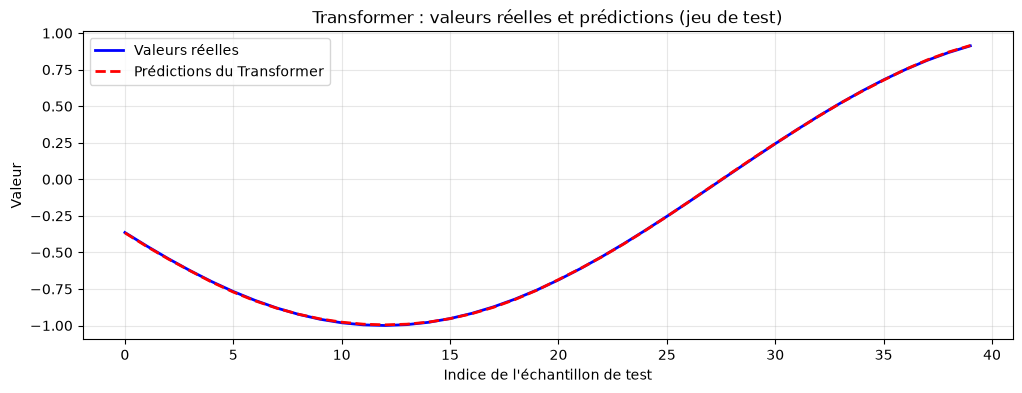

In [10]:
entrainer(modele_transformer, X_train, y_train)
resultats["Transformer"], pred_transformer = tester(modele_transformer, X_test, y_test, "Transformer")

### Comparaison des trois modèles sur le jeu de test

Modèle       | Paramètres |   MSE test
--------------------------------------
RNN          |        321 |   0.000028
LSTM         |       1233 |   0.000003
Transformer  |       2433 |   0.000006


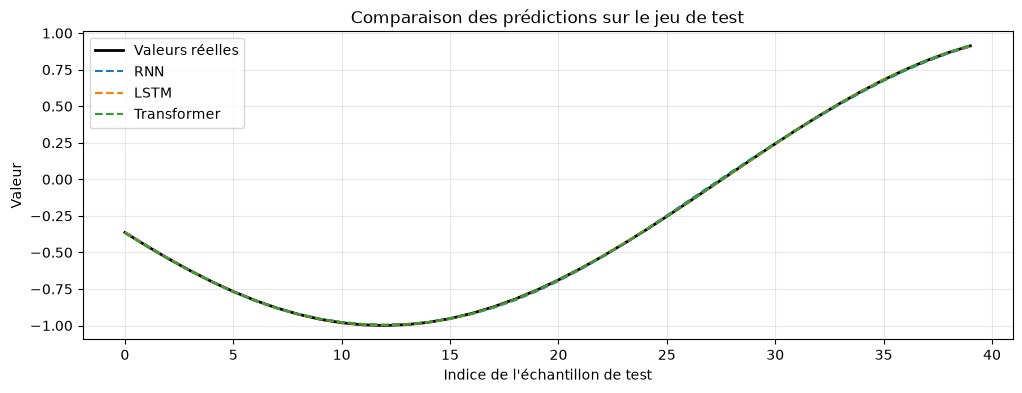

In [11]:
print(f"{'Modèle':<12} | {'Paramètres':>10} | {'MSE test':>10}")
print("-" * 38)
for nom, m in [("RNN", modele_rnn), ("LSTM", modele_lstm), ("Transformer", modele_transformer)]:
    print(f"{nom:<12} | {nb_parametres(m):>10} | {resultats[nom]:>10.6f}")

plt.figure(figsize=(12, 4))
plt.plot(y_test.reshape(-1).numpy(), label="Valeurs réelles", color="black", linewidth=2)
plt.plot(pred_rnn.reshape(-1).numpy(), "--", label="RNN")
plt.plot(pred_lstm.reshape(-1).numpy(), "--", label="LSTM")
plt.plot(pred_transformer.reshape(-1).numpy(), "--", label="Transformer")
plt.title("Comparaison des prédictions sur le jeu de test")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Analyse

- Les trois modèles apprennent très bien la sinusoïde : les erreurs de test (MSE) sont de l'ordre de $10^{-5}$ à $10^{-6}$, et les courbes prédites se superposent aux valeurs réelles.
- Le **LSTM** et le **Transformer** sont plus précis que le **RNN** simple, grâce à leurs portes (LSTM) ou à l'attention qui relie directement les 10 positions (Transformer). Ils utilisent aussi plus de paramètres (≈ 1 200 et ≈ 2 400 contre ≈ 300).
- Le problème est volontairement facile : la sinusoïde est parfaitement régulière et une fenêtre de 10 valeurs suffit à la prolonger. Les écarts entre modèles sont donc faibles ; ils deviennent significatifs sur des séries réelles, plus bruitées et à dépendances longues (voir l'Exercice 1).
- Les résultats peuvent varier légèrement d'une machine à l'autre malgré `torch.manual_seed(42)`.

---
## 5. Modèle de type GPT : prédire la suite d'un texte

GPT-2 est un Transformer **décodeur uniquement**, pré-entraîné (*Generative Pre-trained Transformer*). Son attention est **causale** : chaque token ne voit que les tokens précédents. La génération est **autorégressive** : le modèle prédit un token, l'ajoute au texte, puis recommence.

```
Input : "Artificial intelligence can"  ──►  [Generative Pre-Trained Transformer]  ──►  Output : "help people and organizations ..."
```

> Le premier lancement télécharge le modèle `gpt2` (≈ 500 Mo) depuis Hugging Face.

In [12]:
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

# 1. Charger le tokenizer et le modèle pré-entraîné
nom_modele = "gpt2"
tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele)
modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié
tokenizer_gpt.pad_token = tokenizer_gpt.eos_token
modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id
modele_gpt.eval()

# 2. Transformer le texte en tokens (GPT-2 est entraîné principalement sur de l'anglais)
texte = "Artificial intelligence can help people"
entrees = tokenizer_gpt(texte, return_tensors="pt")
print("Tokens :", tokenizer_gpt.convert_ids_to_tokens(entrees["input_ids"][0]))
print("Dimensions de l'entrée :", tuple(entrees["input_ids"].shape))  # (1, nombre de tokens)

/Users/hajdaoui/IA GENERATIVE MULTI-MODALE/TP4/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1122 17:50:09.450000 38514 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 11906.49it/s]

Tokens : ['Art', 'ificial', 'Ġintelligence', 'Ġcan', 'Ġhelp', 'Ġpeople']
Dimensions de l'entrée : (1, 6)


### Prédiction du token suivant (un seul pas)

Avant d'utiliser `generate`, on regarde ce que le modèle calcule réellement : une distribution de probabilité sur tout le vocabulaire pour le **prochain** token.

In [13]:
with torch.no_grad():
    logits = modele_gpt(**entrees).logits  # (1, L, taille_vocabulaire)
print("Logits :", tuple(logits.shape))

probas = torch.softmax(logits[0, -1, :], dim=-1)  # dernière position → token suivant
top_p, top_i = torch.topk(probas, k=5)
print(f"\nTokens suivants les plus probables après « {texte} » :")
for p, i in zip(top_p, top_i):
    print(f"  {p.item():6.2%} | {tokenizer_gpt.decode([i.item()])!r}")

Logits : (1, 6, 50257)

Tokens suivants les plus probables après « Artificial intelligence can help people » :
   7.17% | ' to'
   5.87% | ' with'
   4.97% | ' better'
   4.73% | ' understand'
   3.62% | ' make'


### Génération autorégressive de la suite du texte

In [14]:
set_seed(42)  # rend l'échantillonnage reproductible

with torch.no_grad():
    sortie = modele_gpt.generate(
        **entrees,
        max_new_tokens=50,     # générer au maximum 50 tokens
        do_sample=True,        # tirage aléatoire des tokens
        temperature=0.8,       # contrôler la diversité
        top_p=0.9,             # échantillonnage nucleus
        pad_token_id=tokenizer_gpt.pad_token_id
    )

texte_genere = tokenizer_gpt.decode(sortie[0], skip_special_tokens=True)
print("Texte d'entrée :", texte)
print("\nTexte généré :")
print(texte_genere)

Texte d'entrée : Artificial intelligence can help people

Texte généré :
Artificial intelligence can help people understand and understand a vast range of things, from our everyday lives to the everyday activities of others, and from our work. For this reason, we think it's important to understand what is and isn't possible.


---
## 6. Modèle de type BERT : prédire un mot masqué

BERT (*Bidirectional Encoder Representations from Transformers*) est un Transformer **encodeur uniquement**. Son attention est **bidirectionnelle** : pour deviner le mot masqué, il utilise le contexte à gauche **et** à droite.

```
Input : "Rabat est la [MASK] du Maroc."  ──►  [Bidirectional Encoder Representation from Transformer]  ──►  Output : "capitale"
```

On utilise `bert-base-multilingual-cased`, qui prend en charge le français.

In [15]:
from transformers import AutoModelForMaskedLM

# 1. Charger le tokenizer et le modèle pré-entraîné
nom_modele = "bert-base-multilingual-cased"
tokenizer_bert = AutoTokenizer.from_pretrained(nom_modele)
modele_bert = AutoModelForMaskedLM.from_pretrained(nom_modele)
modele_bert.eval()


def predire_masque(texte, k=5):
    entrees = tokenizer_bert(texte, return_tensors="pt")
    # Position du token [MASK] (on suppose un seul masque)
    position_masque = (entrees["input_ids"][0] == tokenizer_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

    with torch.no_grad():
        logits = modele_bert(**entrees).logits  # (1, L, taille_vocabulaire)

    probabilites = torch.softmax(logits[0, position_masque, :], dim=-1)
    top_probabilites, top_indices = torch.topk(probabilites, k=k)

    print("Texte  :", texte)
    print("Tokens :", tokenizer_bert.convert_ids_to_tokens(entrees["input_ids"][0]))
    print("Propositions de BERT :")
    for p, i in zip(top_probabilites, top_indices):
        token = tokenizer_bert.decode([i.item()]).strip()
        print(f"  {p.item():6.2%} | {texte.replace(tokenizer_bert.mask_token, token)}")
    print()


# 2. Prédire le mot masqué
predire_masque(f"Rabat est la {tokenizer_bert.mask_token} du Maroc.")
predire_masque(f"Paris est la {tokenizer_bert.mask_token} de la France.")
predire_masque(f"{tokenizer_bert.mask_token} est la capitale du Maroc.")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 11526.42it/s]


[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte  : Rabat est la [MASK] du Maroc.
Tokens : ['[CLS]', 'Rabat', 'est', 'la', '[MASK]', 'du', 'Maroc', '.', '[SEP]']
Propositions de BERT :
  86.07% | Rabat est la capitale du Maroc.
   5.19% | Rabat est la ville du Maroc.
   5.03% | Rabat est la préfecture du Maroc.
   0.85% | Rabat est la Rabat du Maroc.
   0.58% | Rabat est la capital du Maroc.

Texte  : Paris est la [MASK] de la France.
Tokens : ['[CLS]', 'Paris', 'est', 'la', '[MASK]', 'de', 'la', 'France', '.', '[SEP]']
Propositions de BERT :
  36.33% | Paris est la capitale de la France.
  21.09% | Paris est la ville de la France.
   3.16% | Paris est la Cité de la France.
   1.67% | Paris est la préfecture de la France.
   1.64% | Paris est la banlieue de la France.

Texte  : [MASK] est la capitale du Maroc.
Tokens : ['[CLS]', '[MASK]', 'est', 'la', 'capitale', 'du', 'Maroc', '.', '[SEP]']
Propositions de BERT :
  67.50% | Casablanca est la capitale du Maroc.
   7.24% | Rabat est la capitale du Maroc.
   7.19% | Elle est la c

### Analyse : GPT-2 et BERT

**GPT-2 (décodeur, génération autorégressive)**
- Le texte est découpé en **sous-mots** : `Artificial` devient `Art` + `ificial` ; le symbole `Ġ` marque un espace devant le token.
- Pour la dernière position, le modèle produit une distribution sur les **50 257 tokens** du vocabulaire. Après « Artificial intelligence can help people », les candidats les plus probables (*to*, *with*, *better*, *understand*, *make*) sont tous plausibles, et aucun ne dépasse 8 % : la suite d'un texte est naturellement incertaine.
- `generate` répète ce calcul 50 fois en ajoutant à chaque pas le token tiré. Le texte obtenu est grammatical et cohérent sur le thème, mais il contient des maladresses (« understand and understand ») : GPT-2 est un petit modèle (124 M de paramètres) et l'échantillonnage (`temperature=0.8`, `top_p=0.9`) introduit de l'aléa. Une autre graine donnerait une autre suite.

**BERT (encodeur, attention bidirectionnelle)**
- « Rabat est la [MASK] du Maroc. » → **capitale** (86 %). Le modèle combine le contexte à gauche (*Rabat est la*) et à droite (*du Maroc*).
- « Paris est la [MASK] de la France. » → **capitale** également, mais avec moins de confiance (36 %, contre 21 % pour *ville*).
- « [MASK] est la capitale du Maroc. » → **Casablanca** (67,5 %) devant **Rabat** (7 %). C'est une **erreur factuelle** : BERT ne « connaît » pas les faits, il prédit le mot le plus probable d'après les régularités de ses textes d'entraînement. Casablanca, la plus grande ville du Maroc et sa capitale économique, y est probablement très souvent associée au mot *capitale*.

**GPT vs BERT :** GPT voit uniquement le passé (masque causal) et sait **générer** une suite ; BERT voit toute la phrase et sait **compléter** un trou, mais ne génère pas naturellement de texte. Ce sont les mêmes principes que ceux implémentés depuis zéro dans les Exercices 2 et 3.

---
# Deuxième partie : Exercices

## Exercice 1 — Prédiction de la consommation électrique avec un Transformer

**Objectif :** utiliser les **24 dernières heures** de consommation électrique pour prédire la consommation de l'**heure suivante**.

**Dataset :** *Individual Household Electric Power Consumption* (UCI) — une mesure par minute de décembre 2006 à novembre 2010. On utilise la variable `Global_active_power`, agrégée par heure (puissance moyenne en kW).

### 1. Préparation des données

- Lecture du fichier (`?` = valeur manquante), construction de l'horodatage.
- Moyenne horaire ; une heure n'est conservée que si au moins **45 minutes** sur 60 sont renseignées.

In [16]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées (>= 45 minutes sur 60)
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

print("Mesures minute par minute :", len(df))
print("Heures                    :", len(serie), f"({serie.index[0]} → {serie.index[-1]})")
print("Heures manquantes         :", int(serie.isna().sum()))
print(serie.describe().round(3))

Mesures minute par minute : 2075259
Heures                    : 34589 (2006-12-16 17:00:00 → 2010-11-26 21:00:00)
Heures manquantes         : 438
count    34151.000
mean         1.092
std          0.898
min          0.124
25%          0.342
50%          0.803
75%          1.579
max          6.561
Name: mean, dtype: float64


- Découpage **chronologique** 70 % / 15 % / 15 % (entraînement / validation / test).
- Normalisation $z = (x - \mu)/\sigma$ avec $\mu$ et $\sigma$ calculés **uniquement sur l'entraînement**.
- Fenêtres glissantes de 24 heures ; les fenêtres contenant une valeur manquante sont écartées. Chaque fenêtre est affectée à un ensemble selon l'indice de son **heure cible**.

In [17]:
# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()
print(f"Moyenne (train) = {moyenne:.4f} kW | écart-type (train) = {ecart_type:.4f} kW")

# Une entrée contient 24 heures consécutives ; on écarte les fenêtres incomplètes
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]
    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(TensorDataset(X[train_mask], y[train_mask]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[val_mask], y[val_mask]), batch_size=64)
test_loader = DataLoader(TensorDataset(X[test_mask], y[test_mask]), batch_size=64)

print("X :", tuple(X.shape), "| y :", tuple(y.shape))
print("Fenêtres train / val / test :", int(train_mask.sum()), "/", int(val_mask.sum()), "/", int(test_mask.sum()))

Moyenne (train) = 1.0865 kW | écart-type (train) = 0.9287 kW
X : (33791, 24, 1) | y : (33791, 1)
Fenêtres train / val / test : 23805 / 5054 / 4932


### 2. Le modèle `EnergyTransformer`

| Élément | Configuration |
|---|---|
| Projection | `Linear(1, 32)` |
| Encodage positionnel | `Embedding(24, 32)` appris (une position par heure) |
| Encodeur | 2 × `TransformerEncoderLayer(d_model=32, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)` |
| Sortie | `Linear(32, 1)` appliquée à la représentation de la **dernière heure** |

```
Entrée                     : (batch, 24, 1)
Après projection           : (batch, 24, 32)
Après Transformer Encoder  : (batch, 24, 32)
Prédiction                 : (batch, 1)
```

In [18]:
class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24, d_model=32, nhead=4, num_layers=2,
                 dim_feedforward=128, dropout=0.1):
        super().__init__()
        # Projection Linear(1, 32)
        self.projection = nn.Linear(1, d_model)
        # Encodage positionnel appris des 24 heures
        self.positions = nn.Embedding(fenetre, d_model)
        # Deux couches TransformerEncoderLayer
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=num_layers)
        # Linear(32, 1) appliquée à la représentation de la dernière heure
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):
        # x : (batch, 24, 1)
        indices = torch.arange(x.size(1), device=x.device)
        h = self.projection(x) + self.positions(indices).unsqueeze(0)  # (batch, 24, 32)
        h = self.encodeur(h)                                            # (batch, 24, 32)
        return self.sortie(h[:, -1, :])                                 # (batch, 1)


modele_energie = EnergyTransformer()

# Vérification des formes demandées
with torch.no_grad():
    xb = X[:8]
    h = modele_energie.projection(xb)
    print("Entrée                    :", tuple(xb.shape))
    print("Après projection          :", tuple(h.shape))
    pos = modele_energie.positions(torch.arange(24)).unsqueeze(0)
    print("Après Transformer Encoder :", tuple(modele_energie.encodeur(h + pos).shape))
    print("Prédiction                :", tuple(modele_energie(xb).shape))
print("Nombre de paramètres :", sum(p.numel() for p in modele_energie.parameters()))

Entrée                    : (8, 24, 1)
Après projection          : (8, 24, 32)
Après Transformer Encoder : (8, 24, 32)
Prédiction                : (8, 1)
Nombre de paramètres : 26273


### 3. Entraînement et évaluation

Adam (`lr=0.001`), perte MSE, **20 époques au maximum**. À chaque époque, on mesure la perte de validation et on **conserve le modèle ayant la meilleure perte de validation** (copie de son `state_dict`), qui est rechargé à la fin.

Époque  1 | train MSE 0.4681 | val MSE 0.4045  ← meilleur


Époque  2 | train MSE 0.4327 | val MSE 0.3936  ← meilleur


Époque  3 | train MSE 0.4229 | val MSE 0.3906  ← meilleur


Époque  4 | train MSE 0.4170 | val MSE 0.3826  ← meilleur


Époque  5 | train MSE 0.4142 | val MSE 0.4090


Époque  6 | train MSE 0.4137 | val MSE 0.3975


... (10 outputs left out)

Époque 17 | train MSE 0.3954 | val MSE 0.3817


Époque 18 | train MSE 0.3952 | val MSE 0.3814


Époque 19 | train MSE 0.3932 | val MSE 0.3896


Époque 20 | train MSE 0.3933 | val MSE 0.3763  ← meilleur

Modèle retenu : époque 20 (val MSE normalisée = 0.3763)


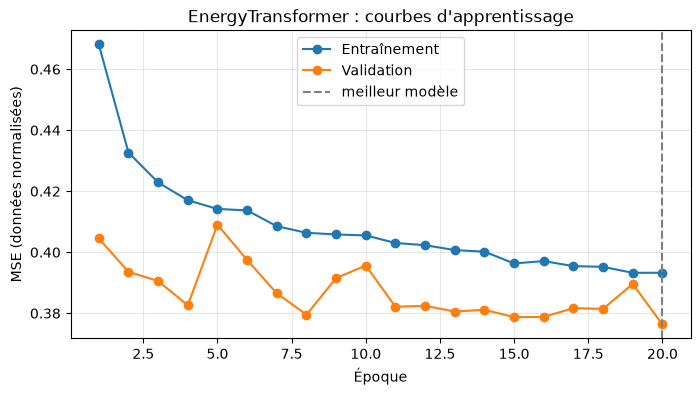

In [19]:
import copy

critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_energie.parameters(), lr=0.001)


def perte_moyenne(modele, loader):
    modele.eval()
    total, nb = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            total += critere(modele(xb), yb).item() * len(xb)
            nb += len(xb)
    return total / nb


meilleure_val = float("inf")
meilleur_etat, meilleure_epoque = None, None
historique = {"train": [], "val": []}

for epoch in range(1, 21):  # au maximum 20 époques
    modele_energie.train()
    total, nb = 0.0, 0
    for xb, yb in train_loader:
        perte = critere(modele_energie(xb), yb)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(xb)
        nb += len(xb)

    perte_train = total / nb
    perte_val = perte_moyenne(modele_energie, val_loader)
    historique["train"].append(perte_train)
    historique["val"].append(perte_val)

    # Conserver le modèle ayant la meilleure perte de validation
    marque = ""
    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = copy.deepcopy(modele_energie.state_dict())
        meilleure_epoque = epoch
        marque = "  ← meilleur"
    print(f"Époque {epoch:2d} | train MSE {perte_train:.4f} | val MSE {perte_val:.4f}{marque}")

modele_energie.load_state_dict(meilleur_etat)
print(f"\nModèle retenu : époque {meilleure_epoque} (val MSE normalisée = {meilleure_val:.4f})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, 21), historique["train"], marker="o", label="Entraînement")
plt.plot(range(1, 21), historique["val"], marker="o", label="Validation")
plt.axvline(meilleure_epoque, color="gray", linestyle="--", label="meilleur modèle")
plt.xlabel("Époque")
plt.ylabel("MSE (données normalisées)")
plt.title("EnergyTransformer : courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

On revient ensuite à l'échelle originale ($\hat{x} = z \cdot \sigma + \mu$) pour calculer la **MAE** et la **RMSE en kW** sur le test, et on compare à deux références évaluées sur **les mêmes heures** :

- **Persistance** : prédire la valeur de la dernière heure observée ($t-1$) ;
- **Référence journalière** : prédire la valeur observée 24 heures auparavant ($t-24$), c'est-à-dire la première valeur de la fenêtre.

L'évaluation se fait heure par heure : chaque prédiction utilise les 24 mesures réellement observées avant son heure cible.

In [20]:
# Prédictions sur le test, puis retour à l'échelle originale (kW)
modele_energie.eval()
with torch.no_grad():
    pred_norm = torch.cat([modele_energie(xb) for xb, _ in test_loader]).squeeze(-1).numpy()

pred_kw = pred_norm * ecart_type + moyenne
reel_kw = y[test_mask].squeeze(-1).numpy() * ecart_type + moyenne

# Références, évaluées sur exactement les mêmes heures cibles
X_test_kw = X[test_mask].squeeze(-1).numpy() * ecart_type + moyenne
persistance_kw = X_test_kw[:, -1]  # valeur de la dernière heure observée (t-1)
journaliere_kw = X_test_kw[:, 0]   # valeur observée 24 heures auparavant (t-24)


def mae(a, b):
    return np.mean(np.abs(a - b))


def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))


tableau = pd.DataFrame({
    "MAE (kW)": [mae(pred_kw, reel_kw), mae(persistance_kw, reel_kw), mae(journaliere_kw, reel_kw)],
    "RMSE (kW)": [rmse(pred_kw, reel_kw), rmse(persistance_kw, reel_kw), rmse(journaliere_kw, reel_kw)],
}, index=["EnergyTransformer", "Persistance (t-1)", "Référence journalière (t-24)"])
print(f"Jeu de test : {len(reel_kw)} heures\n")
print(tableau.round(4))

Jeu de test : 4932 heures

                              MAE (kW)  RMSE (kW)
EnergyTransformer               0.3501     0.4970
Persistance (t-1)               0.3892     0.5884
Référence journalière (t-24)    0.5133     0.7639


Tracé des prédictions et des observations sur **sept jours consécutifs** (168 heures sans valeur manquante) du jeu de test :

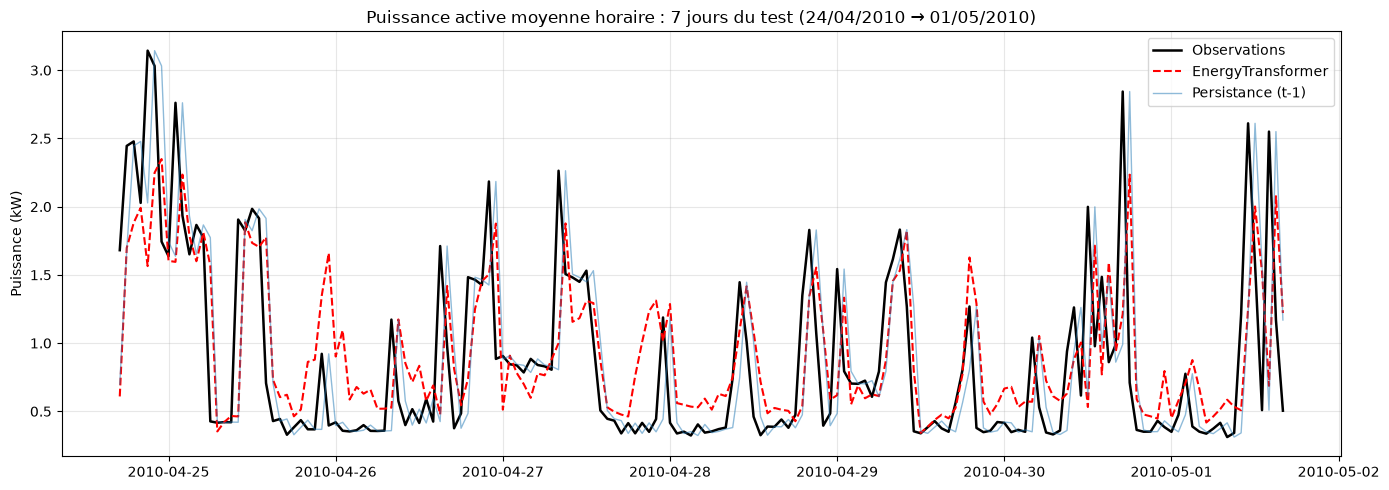

In [21]:
# Sept jours consécutifs (168 heures) du test sans valeur manquante
indices_test = dates_cibles[test_mask]
debut = next(
    k for k in range(len(indices_test) - 168)
    if indices_test[k + 167] - indices_test[k] == 167
)
sl = slice(debut, debut + 168)
dates = serie.index[indices_test[sl]]

plt.figure(figsize=(14, 5))
plt.plot(dates, reel_kw[sl], label="Observations", color="black", linewidth=1.8)
plt.plot(dates, pred_kw[sl], label="EnergyTransformer", color="red", linestyle="--", linewidth=1.5)
plt.plot(dates, persistance_kw[sl], label="Persistance (t-1)", color="tab:blue", alpha=0.5, linewidth=1)
plt.title(f"Puissance active moyenne horaire : 7 jours du test ({dates[0]:%d/%m/%Y} → {dates[-1]:%d/%m/%Y})")
plt.ylabel("Puissance (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Expériences complémentaires

Pour répondre aux questions 2 et 3 avec des mesures plutôt qu'avec des intuitions, on réentraîne le même modèle (mêmes hyperparamètres, même sélection sur la validation) dans deux variantes :

- **(a)** une fenêtre de **168 heures** (une semaine) au lieu de 24 ;
- **(b)** la fenêtre de 24 heures, avec en plus l'**heure de la journée** et le **jour de la semaine**, encodés par $\sin/\cos$ pour respecter leur caractère cyclique (23 h est proche de 0 h). Pour chaque pas de la fenêtre, on fournit le calendrier de l'heure *suivante*, de sorte que la dernière position décrive l'heure cible. Ces informations sont connues à l'avance : ce n'est pas une fuite.

Toutes les variantes sont comparées sur les **mêmes heures de test** (celles pour lesquelles une fenêtre complète de 168 h existe).

> ⏱ Cette cellule prend plusieurs minutes (la fenêtre de 168 h rend l'attention 7 fois plus longue).

In [22]:
# Expériences complémentaires pour les questions de réflexion :
#   (a) fenêtre de 168 heures (une semaine) au lieu de 24
#   (b) fenêtre de 24 heures + heure de la journée et jour de la semaine (encodage sin/cos)
class EnergyTransformerMulti(EnergyTransformer):
    # Même architecture, mais la projection accepte plusieurs variables par heure
    def __init__(self, fenetre, nb_variables):
        super().__init__(fenetre=fenetre)
        self.projection = nn.Linear(nb_variables, 32)


# Variables calendaires de chaque heure (connues à l'avance, donc sans fuite d'information)
heures = serie.index.hour.to_numpy()
jours = serie.index.dayofweek.to_numpy()
calendrier = np.stack([
    np.sin(2 * np.pi * heures / 24), np.cos(2 * np.pi * heures / 24),
    np.sin(2 * np.pi * jours / 7), np.cos(2 * np.pi * jours / 7),
], axis=1)


def construire(fenetre, avec_calendrier):
    Xs, ys, idx = [], [], []
    for i in range(fenetre, n):
        sequence = valeurs[i - fenetre:i]
        if np.isfinite(sequence).all() and np.isfinite(valeurs[i]):
            if avec_calendrier:
                # calendrier de l'heure observée décalé d'un pas : la dernière ligne décrit l'heure cible
                sequence = np.column_stack([sequence, calendrier[i - fenetre + 1:i + 1]])
            Xs.append(sequence)
            ys.append(valeurs[i])
            idx.append(i)
    Xs = torch.tensor(np.array(Xs), dtype=torch.float32)
    if Xs.dim() == 2:
        Xs = Xs.unsqueeze(-1)
    return Xs, torch.tensor(np.array(ys), dtype=torch.float32).unsqueeze(-1), np.array(idx)


def experience(fenetre, avec_calendrier, heures_communes):
    torch.manual_seed(42)
    Xe, ye, idx = construire(fenetre, avec_calendrier)
    tr, va = idx < fin_train, (idx >= fin_train) & (idx < fin_val)
    te = np.isin(idx, heures_communes)  # mêmes heures de test pour toutes les variantes
    modele = EnergyTransformerMulti(fenetre, Xe.shape[-1])
    opt = torch.optim.Adam(modele.parameters(), lr=0.001)
    tl = DataLoader(TensorDataset(Xe[tr], ye[tr]), batch_size=64, shuffle=True)
    vl = DataLoader(TensorDataset(Xe[va], ye[va]), batch_size=64)
    meilleur, etat = float("inf"), None
    for _ in range(20):
        modele.train()
        for xb, yb in tl:
            perte = critere(modele(xb), yb)
            opt.zero_grad()
            perte.backward()
            opt.step()
        pv = perte_moyenne(modele, vl)
        if pv < meilleur:
            meilleur, etat = pv, copy.deepcopy(modele.state_dict())
    modele.load_state_dict(etat)
    modele.eval()
    with torch.no_grad():
        p = modele(Xe[te]).squeeze(-1).numpy() * ecart_type + moyenne
    r = ye[te].squeeze(-1).numpy() * ecart_type + moyenne
    return mae(p, r), rmse(p, r)


# Heures de test utilisables par toutes les variantes (fenêtre de 168 h complète)
_, _, idx168 = construire(168, False)
heures_communes = np.intersect1d(idx168[idx168 >= fin_val], dates_cibles[test_mask])
sel = np.isin(dates_cibles[test_mask], heures_communes)

lignes = {
    "Persistance (t-1)": (mae(persistance_kw[sel], reel_kw[sel]), rmse(persistance_kw[sel], reel_kw[sel])),
    "EnergyTransformer 24 h": (mae(pred_kw[sel], reel_kw[sel]), rmse(pred_kw[sel], reel_kw[sel])),
}
lignes["Fenêtre 168 h"] = experience(168, False, heures_communes)
lignes["24 h + heure et jour"] = experience(24, True, heures_communes)

comparaison = pd.DataFrame(lignes, index=["MAE (kW)", "RMSE (kW)"]).T
print(f"Heures de test communes : {len(heures_communes)}\n")
print(comparaison.round(4))

/var/folders/ms/63vgmytn49z1hq2nlcc_fx840000gn/T/ipykernel_38514/1025869092.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  jours = serie.index.dayofweek.to_numpy()


Heures de test communes : 4644

                        MAE (kW)  RMSE (kW)
Persistance (t-1)         0.3862     0.5853
EnergyTransformer 24 h    0.3466     0.4930
Fenêtre 168 h             0.3274     0.4809
24 h + heure et jour      0.3451     0.4817


### 4. Questions de réflexion

**Le Transformer améliore-t-il les deux références ?**

Oui. Sur les 4 932 heures du test, l'`EnergyTransformer` obtient la plus faible MAE et la plus faible RMSE (voir le tableau). Il fait mieux que la **persistance** (environ −10 % de MAE et −15 % de RMSE) et nettement mieux que la **référence journalière**, qui est la plus mauvaise : la consommation d'un foyer à une heure donnée varie beaucoup d'un jour à l'autre. Le gain est plus marqué sur la RMSE, qui pénalise les grandes erreurs : le modèle anticipe mieux les montées et les descentes, alors que la persistance a toujours une heure de retard. L'amélioration reste modeste en valeur absolue : la consommation d'un seul foyer contient une forte part aléatoire (allumage d'un four, d'une machine…) qu'aucun modèle ne peut prévoir à partir du seul historique. Le graphique sur 7 jours le montre : les pics brusques sont sous-estimés ou arrivent avec retard.

**Une fenêtre de 168 heures permet-elle de mieux capturer les habitudes hebdomadaires ?**

D'après l'expérience (a), **oui, légèrement** : sur les mêmes heures de test, la MAE passe d'environ 0,347 à 0,327 kW et la RMSE de 0,493 à 0,481 kW. Avec une semaine d'historique, le modèle peut s'appuyer sur la même heure des jours précédents et sur le même jour de la semaine précédente (différence semaine / week-end). En contrepartie, l'attention coûte $O(L^2)$ : la fenêtre de 168 h multiplie le nombre de paires par $7^2 = 49$, et l'entraînement est nettement plus long. Il y a aussi moins de fenêtres complètes, car une seule heure manquante sur 168 invalide la fenêtre. Ce résultat repose sur un seul entraînement par variante ; un écart de cet ordre devrait être confirmé avec plusieurs graines.

**Quel serait l'intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**

La consommation suit des cycles quotidiens (pics du matin et du soir) et hebdomadaires (week-end). Avec 24 h de valeurs seules, le modèle doit **deviner** à quelle heure il se trouve à partir de la forme de la courbe, et il ne peut pas connaître le jour de la semaine. Fournir ces variables, encodées par $\sin/\cos$ pour respecter leur cyclicité, lui donne directement cette information, qui est connue à l'avance pour l'heure cible. Dans l'expérience (b), le gain est faible sur la MAE (≈ 0,347 → 0,345 kW) mais net sur la RMSE (≈ 0,493 → 0,482 kW) : le modèle anticipe mieux les grandes variations liées aux horaires. On obtient un gain proche de celui de la fenêtre de 168 h avec une fenêtre 7 fois plus courte, donc pour un coût bien moindre. On pourrait aussi ajouter les jours fériés, les vacances ou la température extérieure.

**Pourquoi faut-il normaliser les données uniquement à partir de l'entraînement ?**

Pour éviter une **fuite d'information**. La moyenne et l'écart-type calculés sur toute la série contiendraient de l'information sur la période de validation et de test, c'est-à-dire sur le futur (par exemple une baisse de consommation en 2010). Or, en situation réelle, on ne connaît que le passé au moment d'entraîner le modèle. Les paramètres de normalisation font partie du modèle : ils doivent être estimés sur l'entraînement, puis appliqués tels quels à la validation et au test. Sinon, l'évaluation serait optimiste et ne refléterait pas les performances réelles.

**La cible étant une puissance moyenne en kW, comment adapter la préparation pour prédire une énergie consommée en kWh ?**

L'énergie est l'intégrale de la puissance dans le temps : $E\,[\text{kWh}] = P\,[\text{kW}] \times \Delta t\,[\text{h}]$. Chaque mesure minute représente $P_{\text{min}} \times \frac{1}{60}$ kWh. On remplace donc l'agrégation horaire `mean` par une **somme** : `resample("h").sum() / 60`. Pour une heure complète, l'énergie horaire en kWh a numériquement la même valeur que la puissance moyenne en kW, mais la somme est sensible aux **minutes manquantes**. Il faut alors soit ne garder que les heures complètes, soit estimer l'énergie par $\bar{P} \times 1\,\text{h}$ (la moyenne des minutes présentes) lorsqu'au moins 45 minutes sont renseignées, ce qui revient à extrapoler les minutes manquantes. Les métriques MAE et RMSE s'expriment alors en kWh. Pour prédire l'énergie d'une journée, on agrégerait par jour (`resample("D")`) avec une cible égale à la somme des 24 heures.

---
## Exercice 2 — Mini-GPT pour générer du texte

**Objectif :** construire un Transformer **autorégressif** qui prédit le **prochain caractère**, entraîné depuis zéro avec une tokenisation par caractères.

### Données

Le fichier `corpus.txt` (fourni à côté du notebook) contient environ quatre pages de texte en français sur les réseaux de neurones et le Transformer. Chaque caractère distinct reçoit un identifiant (`stoi` / `itos`).

Pour une entrée `Bonjou`, la cible est le texte **décalé d'un caractère** (`onjour`) : chaque position apprend à prédire le caractère suivant.

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
taille_vocabulaire = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

print("Nombre de caractères du corpus :", len(texte))
print("Taille du vocabulaire          :", taille_vocabulaire)
print("Vocabulaire :", "".join(caracteres).replace("\n", "\\n"))

# Exemple d'une paire entrée/cible : la cible est l'entrée décalée d'un caractère
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]
print("\nEntrée :", repr("".join(itos[i.item()] for i in x[:20])))
print("Cible  :", repr("".join(itos[i.item()] for i in y[:20])))

Nombre de caractères du corpus : 10422
Taille du vocabulaire          : 56
Vocabulaire : \n ',-.:ABCDEGILMOPRSTUabcdefghijlmnopqrstuvwxyÀàâçèéêîôû

Entrée : 'Les réseaux de neuro'
Cible  : 'es réseaux de neuron'


On réserve les derniers 10 % du texte pour la **validation** (texte jamais vu). Les lots d'entraînement sont des extraits de 64 caractères tirés au hasard.

In [24]:
# Découpage : 90 % du texte pour l'entraînement, 10 % (la fin) pour la validation
coupure = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:coupure], tokens[coupure:]


def lot_aleatoire(donnees, batch_size=64, longueur=64):
    # Tire des positions de départ au hasard et construit (entrées, cibles décalées)
    debuts = torch.randint(0, len(donnees) - longueur - 1, (batch_size,))
    xb = torch.stack([donnees[d:d + longueur] for d in debuts])
    yb = torch.stack([donnees[d + 1:d + longueur + 1] for d in debuts])
    return xb, yb


xb, yb = lot_aleatoire(tokens_train)
print("Identifiants en entrée :", tuple(xb.shape))
print("Cibles                 :", tuple(yb.shape))

Identifiants en entrée : (64, 64)
Cibles                 : (64, 64)


### Le modèle

**Bloc GPT** (*pre-LayerNorm*) :

```
x ──► LayerNorm ──► Attention multi-têtes CAUSALE ──► (+) ──► LayerNorm ──► MLP 64→256→64 (GELU) ──► (+) ──►
 └──────────────────────────────────────────────────────┘ └──────────────────────────────────────────────┘
               première connexion résiduelle                        seconde connexion résiduelle
```

Le **masque causal** est une matrice triangulaire supérieure : `True` au-dessus de la diagonale signifie « relation interdite », donc la position $t$ ne voit que les positions $0 \dots t$.

**Modèle complet :** embeddings de caractères + embeddings de positions (dimension 64), **2 blocs**, **4 têtes**, une normalisation finale et une projection vers le vocabulaire.

```
Identifiants en entrée : (batch, 64)
Représentations        : (batch, 64, 64)
Logits                 : (batch, 64, taille_vocabulaire)
Cibles                 : (batch, 64)
```

In [25]:
class BlocGPT(nn.Module):
    def __init__(self, d_model=64, nhead=4, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)          # normalisation avant l'attention
        self.attention = nn.MultiheadAttention(d_model, nhead, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)          # seconde normalisation
        self.mlp = nn.Sequential(                   # MLP 64 → 256 → 64 avec GELU
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, causal=True):
        T = x.shape[1]
        # True signifie : cette relation d'attention est interdite (regarder le futur)
        masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)
        h = self.norm1(x)
        a, _ = self.attention(h, h, h, attn_mask=masque if causal else None, need_weights=False)
        x = x + a                       # première connexion résiduelle
        x = x + self.mlp(self.norm2(x)) # seconde connexion résiduelle
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=64, d_model=64, nhead=4, nb_blocs=2,
                 dropout=0.1, causal=True):
        super().__init__()
        self.longueur_max = longueur_max
        self.causal = causal
        self.embedding_caracteres = nn.Embedding(taille_vocabulaire, d_model)
        self.embedding_positions = nn.Embedding(longueur_max, d_model)
        self.dropout = nn.Dropout(dropout)
        self.blocs = nn.ModuleList([BlocGPT(d_model, nhead, dropout) for _ in range(nb_blocs)])
        self.norm_finale = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, taille_vocabulaire)  # projection vers le vocabulaire

    def representations(self, ids):
        T = ids.shape[1]
        positions = torch.arange(T, device=ids.device)
        x = self.dropout(self.embedding_caracteres(ids) + self.embedding_positions(positions))
        for bloc in self.blocs:
            x = bloc(x, causal=self.causal)
        return self.norm_finale(x)         # (batch, T, 64)

    def forward(self, ids):
        return self.tete(self.representations(ids))  # (batch, T, taille_vocabulaire)


torch.manual_seed(42)
gpt = MiniGPT(taille_vocabulaire, dropout=0.2)
print("Nombre de paramètres :", sum(p.numel() for p in gpt.parameters()))

with torch.no_grad():
    print("Identifiants en entrée :", tuple(xb.shape))
    print("Représentations        :", tuple(gpt.representations(xb).shape))
    print("Logits                 :", tuple(gpt(xb).shape))
    print("Cibles                 :", tuple(yb.shape))

Nombre de paramètres : 111416
Identifiants en entrée : (64, 64)
Représentations        : (64, 64, 64)
Logits                 : (64, 64, 56)
Cibles                 : (64, 64)


### Entraînement

Perte d'**entropie croisée sur toutes les positions** : les logits `(batch, 64, V)` sont aplatis en `(batch·64, V)` et comparés aux cibles `(batch·64,)`. Optimiseur AdamW.

Le corpus est petit (≈ 10 000 caractères) et le modèle sur-apprend vite : la perte d'entraînement continue à baisser alors que la perte de validation remonte. Comme dans l'exercice 1, on évalue régulièrement et on **conserve le modèle ayant la meilleure perte de validation**.

Perte initiale attendue ≈ ln(56) = 4.025



Itération     1 | perte train 4.004 | perte val 3.986  ← meilleur


Itération   100 | perte train 2.323 | perte val 2.389  ← meilleur


Itération   200 | perte train 2.180 | perte val 2.246  ← meilleur


Itération   300 | perte train 1.964 | perte val 2.080  ← meilleur


Itération   400 | perte train 1.742 | perte val 1.950  ← meilleur


... (7 outputs left out)

Itération  1200 | perte train 0.837 | perte val 1.917


Itération  1300 | perte train 0.783 | perte val 1.981


Itération  1400 | perte train 0.728 | perte val 1.987


Itération  1500 | perte train 0.683 | perte val 2.037

Modèle retenu : itération 600 (perte val = 1.835)


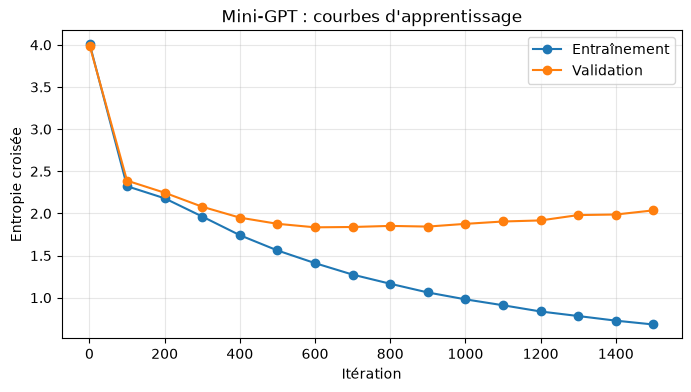

In [26]:
def perte_lm(modele, xb, yb):
    logits = modele(xb)
    # Entropie croisée sur toutes les positions : (batch*T, V) contre (batch*T,)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))


@torch.no_grad()
def evaluer(modele, donnees, nb_lots=20):
    modele.eval()
    g = torch.Generator().manual_seed(0)
    pertes = []
    for _ in range(nb_lots):
        debuts = torch.randint(0, len(donnees) - 65, (64,), generator=g)
        xb = torch.stack([donnees[d:d + 64] for d in debuts])
        yb = torch.stack([donnees[d + 1:d + 65] for d in debuts])
        pertes.append(perte_lm(modele, xb, yb).item())
    modele.train()
    return sum(pertes) / len(pertes)


import copy


def entrainer_gpt(modele, nb_iterations, lr=2e-3, afficher_tous=100):
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=0.1)
    historique = []
    meilleure_val, meilleur_etat, meilleure_it = float("inf"), None, None
    modele.train()
    for it in range(1, nb_iterations + 1):
        xb, yb = lot_aleatoire(tokens_train)
        perte = perte_lm(modele, xb, yb)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        if it % afficher_tous == 0 or it == 1:
            pt, pv = evaluer(modele, tokens_train), evaluer(modele, tokens_val)
            historique.append((it, pt, pv))
            marque = ""
            if pv < meilleure_val:  # conserver le modèle ayant la meilleure perte de validation
                meilleure_val, meilleur_etat, meilleure_it = pv, copy.deepcopy(modele.state_dict()), it
                marque = "  ← meilleur"
            print(f"Itération {it:5d} | perte train {pt:.3f} | perte val {pv:.3f}{marque}")
    modele.load_state_dict(meilleur_etat)
    print(f"\nModèle retenu : itération {meilleure_it} (perte val = {meilleure_val:.3f})")
    return historique


print(f"Perte initiale attendue ≈ ln({taille_vocabulaire}) = {torch.log(torch.tensor(float(taille_vocabulaire))):.3f}\n")
torch.manual_seed(42)
historique_gpt = entrainer_gpt(gpt, nb_iterations=1500)

its, pts, pvs = zip(*historique_gpt)
plt.figure(figsize=(8, 4))
plt.plot(its, pts, marker="o", label="Entraînement")
plt.plot(its, pvs, marker="o", label="Validation")
plt.xlabel("Itération")
plt.ylabel("Entropie croisée")
plt.title("Mini-GPT : courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Vérification essentielle : le modèle ne voit pas le futur

En mode `eval()`, on modifie le caractère en position 40 : les logits des positions 0 à 39 doivent rester **strictement identiques**, seules les positions ≥ 40 peuvent changer.

In [27]:
# Vérification essentielle : modifier un caractère futur ne modifie pas les logits des positions précédentes
gpt.eval()
with torch.no_grad():
    ids = tokens_val[:64].unsqueeze(0).clone()
    logits_avant = gpt(ids)

    k = 40
    ids_modifies = ids.clone()
    ids_modifies[0, k] = (ids[0, k] + 1) % taille_vocabulaire  # on change le caractère en position 40
    logits_apres = gpt(ids_modifies)

ecart_passe = (logits_avant[0, :k] - logits_apres[0, :k]).abs().max().item()
ecart_futur = (logits_avant[0, k:] - logits_apres[0, k:]).abs().max().item()
print(f"Caractère modifié en position {k} : {itos[ids[0, k].item()]!r} → {itos[ids_modifies[0, k].item()]!r}")
print(f"Écart max des logits aux positions 0..{k - 1} : {ecart_passe:.2e}")
print(f"Écart max des logits aux positions {k}..63 : {ecart_futur:.2e}")
assert torch.allclose(logits_avant[0, :k], logits_apres[0, :k], atol=1e-6), "fuite d'information du futur !"
print("✔ Le masque causal fonctionne : le passé ne voit pas le futur.")

Caractère modifié en position 40 : ' ' → "'"
Écart max des logits aux positions 0..39 : 0.00e+00
Écart max des logits aux positions 40..63 : 5.38e+00
✔ Le masque causal fonctionne : le passé ne voit pas le futur.


### Génération de 200 caractères et effet de la température

À chaque pas : on garde au plus 64 caractères de contexte, on divise les logits de la dernière position par la température $T$, on applique le softmax et on **échantillonne** le caractère suivant, que l'on ajoute au texte.

$$
p_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}
$$

In [28]:
@torch.no_grad()
def generer(modele, amorce, nb_caracteres=200, temperature=1.0, graine=0):
    modele.eval()
    g = torch.Generator().manual_seed(graine)
    ids = torch.tensor([[stoi[c] for c in amorce]], dtype=torch.long)
    for _ in range(nb_caracteres):
        contexte = ids[:, -modele.longueur_max:]              # au plus 64 caractères de contexte
        logits = modele(contexte)[:, -1, :] / temperature     # scores du caractère suivant
        probabilites = torch.softmax(logits, dim=-1)
        suivant = torch.multinomial(probabilites, num_samples=1, generator=g)  # échantillonnage
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())


amorce = "Le Transformer "
for temperature in [0.5, 1.0, 1.5]:
    print(f"===== Température {temperature} =====")
    print(generer(gpt, amorce, nb_caracteres=200, temperature=temperature))
    print()

===== Température 0.5 =====
Le Transformer l'attention représentions approduiser les des mots mots des mots. Avects de des la présend produitent le sur carant l'atter partions de de pouver partend, le Trans la gradui es des de parans de de la 

===== Température 1.0 =====


Le Transformer un decteux cement coms à la modèle prodients, et pas proCes mots. Avectui par lis fammèti-stre l'ention. La par la gla trantration n'e vagententrentraîne, suropon réce ints éle donne payte, les quelie

===== Température 1.5 =====
Le Transformer un decteux cemetruchospà la, posuMeurs ime sopriofammpérepre dui. Ave cul danctil fammètiéstte l'ela Ition de sonne l'it.



BTêheun'a vage, entron rainversèons aux. Laires élecûonds payts, lEAu l'ouv



Effet de la température sur la distribution du caractère suivant après l'amorce « Le modèle » :

In [29]:
# Effet de la température sur la distribution du caractère suivant
with torch.no_grad():
    ids = torch.tensor([[stoi[c] for c in "Le modèle "]])
    logits = gpt(ids)[0, -1]
for temperature in [0.5, 1.0, 1.5]:
    p = torch.softmax(logits / temperature, dim=-1)
    top_p, top_i = torch.topk(p, 3)
    entropie = -(p * p.clamp_min(1e-12).log()).sum().item()
    propositions = ", ".join(f"{itos[i.item()]!r}: {v.item():.1%}" for v, i in zip(top_p, top_i))
    print(f"T = {temperature} | entropie = {entropie:.2f} | top-3 : {propositions}")

T = 0.5 | entropie = 2.16 | top-3 : 'p': 31.1%, 'm': 17.0%, 'd': 13.3%
T = 1.0 | entropie = 2.86 | top-3 : 'p': 15.5%, 'm': 11.5%, 'd': 10.1%
T = 1.5 | entropie = 3.20 | top-3 : 'p': 10.5%, 'm': 8.6%, 'd': 7.9%


### Expérience : entraînement sans masque causal

Pour répondre à la première question, on entraîne le même modèle **sans masque** pendant 500 itérations.

In [30]:
# Expérience : que se passe-t-il si l'on supprime le masque causal pendant l'entraînement ?
torch.manual_seed(42)
gpt_sans_masque = MiniGPT(taille_vocabulaire, causal=False)
print("Entraînement SANS masque causal (500 itérations) :")
historique_sans = entrainer_gpt(gpt_sans_masque, nb_iterations=500)

print("\nGénération (T = 1.0) avec le modèle sans masque :")
print(generer(gpt_sans_masque, amorce, nb_caracteres=200, temperature=1.0))

Entraînement SANS masque causal (500 itérations) :


Itération     1 | perte train 4.004 | perte val 3.982  ← meilleur


Itération   100 | perte train 2.265 | perte val 2.318  ← meilleur


Itération   200 | perte train 0.107 | perte val 0.150  ← meilleur


Itération   300 | perte train 0.047 | perte val 0.060  ← meilleur


Itération   400 | perte train 0.040 | perte val 0.045  ← meilleur


Itération   500 | perte train 0.038 | perte val 0.042  ← meilleur

Modèle retenu : itération 500 (perte val = 0.042)

Génération (T = 1.0) avec le modèle sans masque :
Le Transformer serenetasfasfretrmotororérarorrerM ffffomforsfrmofffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffffff


### Réponses aux questions

**Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**

Le modèle **triche**. Sans masque, la position $t$ peut regarder la position $t+1$, or le caractère en $t+1$ est exactement la cible de la position $t$. Il suffit au modèle d'apprendre à **recopier son voisin de droite** : la perte s'effondre en quelques centaines d'itérations (≈ 0,04 contre ≈ 1,8 pour le modèle causal), même sur la validation, puisque la validation lui donne aussi accès au futur. Cette perte très basse est trompeuse : le modèle n'a rien appris d'utile pour la génération. Au moment de générer, la dernière position n'a **pas** de voisin à droite (le futur n'existe pas encore) : le modèle se retrouve dans une situation jamais rencontrée pendant l'entraînement et produit une suite incohérente qui dégénère en répétitions (`ffffff…`), comme le montre l'expérience ci-dessus.

**Quel effet la température a-t-elle sur la génération ?**

La température divise les logits avant le softmax.
- $T < 1$ (ex. 0,5) **accentue** les écarts : la distribution devient plus pointue (entropie plus faible), le modèle choisit presque toujours les caractères les plus probables. Le texte est plus « sûr », mais aussi plus répétitif.
- $T = 1$ échantillonne selon la distribution apprise.
- $T > 1$ (ex. 1,5) **aplatit** la distribution (entropie plus élevée) : des caractères peu probables sont tirés plus souvent, le texte devient plus varié mais aussi beaucoup plus incohérent (mots inventés, ponctuation au hasard).

On l'observe sur la distribution du caractère suivant : l'entropie augmente avec $T$ et la probabilité du caractère le plus probable diminue. Lorsque $T \to 0$, on retrouve la génération gloutonne (*argmax*).

**Pourquoi faut-il décaler les cibles d'une position ?**

Parce que la tâche est de **prédire le caractère suivant**. Avec `x = tokens[i : i+64]` et `y = tokens[i+1 : i+65]`, la cible de la position $t$ est le caractère $t+1$ : la position $t$, qui voit les caractères $0 \dots t$ grâce au masque causal, apprend $P(c_{t+1} \mid c_0, \dots, c_t)$. Sans décalage, la cible de la position $t$ serait le caractère $t$ lui-même, qu'elle voit déjà en entrée : le modèle apprendrait à recopier son entrée, ce qui est inutile pour générer. Le décalage permet aussi d'obtenir **64 exemples d'apprentissage par séquence** (un par position) en une seule passe.

**Limite observée :** avec un corpus d'environ 10 000 caractères, le modèle apprend l'orthographe des mots fréquents, les espaces, la ponctuation et des fragments de phrases du corpus, mais la perte de validation (≈ 1,8) reste bien au-dessus de la perte d'entraînement : il mémorise plus qu'il ne généralise. Un corpus plus grand serait nécessaire pour produire un texte cohérent.

---
## Exercice 3 — Mini-BERT pour retrouver des mots masqués

**Objectif :** entraîner un Transformer **bidirectionnel** à reconstruire des mots masqués grâce au contexte situé **à gauche et à droite** (objectif *Masked Language Modeling* de BERT).

### Données

On construit un petit corpus de phrases simples de la forme *sujet + verbe + complément + lieu + moment*. Le sujet détermine les verbes et les lieux possibles, le verbe détermine les compléments : le contexte des deux côtés est donc informatif. Par exemple, `prépare` est partagé par le boulanger et le cuisinier ; seul le contexte à droite (*le pain*, *la boulangerie* ou *une soupe*, *la cuisine*) permet de les distinguer.

Les phrases sont mélangées puis séparées en **80 % entraînement / 20 % validation** : les phrases de validation ne sont jamais vues pendant l'entraînement.

In [31]:
import random
import itertools
import torch
import torch.nn as nn
import torch.nn.functional as F

random.seed(42)
torch.manual_seed(42)

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
SPECIAUX = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]

# Petit corpus de phrases : sujet + verbe + complément + lieu + moment.
# Le sujet détermine les verbes et les lieux possibles, le verbe détermine les compléments :
# le contexte à gauche ET à droite d'un mot aide donc à le retrouver.
profils = {
    "le chat":        ({"mange": ["des croquettes", "du poisson"], "chasse": ["une souris", "un oiseau"]},
                       ["dans le jardin", "sur le canapé"]),
    "le boulanger":   ({"prépare": ["le pain", "des croissants"], "vend": ["des baguettes", "des gâteaux"]},
                       ["dans la boulangerie", "au marché"]),
    "l'étudiant":     ({"lit": ["un livre", "un article"], "écrit": ["un rapport", "un programme"]},
                       ["à la bibliothèque", "à l'université"]),
    "la professeure": ({"explique": ["le cours", "la leçon"], "corrige": ["les copies", "les examens"]},
                       ["dans la classe", "au lycée"]),
    "le médecin":     ({"soigne": ["les patients", "un enfant"], "examine": ["une radio", "un malade"]},
                       ["à l'hôpital", "au cabinet"]),
    "le jardinier":   ({"arrose": ["les fleurs", "les tomates"], "plante": ["un arbre", "des salades"]},
                       ["dans le potager", "au parc"]),
    "le pilote":      ({"pilote": ["un avion", "un hélicoptère"], "contrôle": ["les moteurs", "le radar"]},
                       ["à l'aéroport", "dans le ciel"]),
    "le cuisinier":   ({"prépare": ["une soupe", "un gâteau"], "coupe": ["des légumes", "la viande"]},
                       ["dans la cuisine", "au restaurant"]),
}
moments = ["le matin", "le soir", "chaque jour", "aujourd'hui"]

phrases = []
for sujet, (actions, lieux) in profils.items():
    for verbe, complements in actions.items():
        for complement, lieu, moment in itertools.product(complements, lieux, moments):
            phrases.append(f"{sujet} {verbe} {complement} {lieu} {moment}")

random.shuffle(phrases)
coupure = int(0.8 * len(phrases))
phrases_train, phrases_val = phrases[:coupure], phrases[coupure:]  # phrases de validation jamais vues

print("Nombre de phrases :", len(phrases), f"(train {len(phrases_train)}, val {len(phrases_val)})")
for p in phrases[:5]:
    print("  ", p)

Nombre de phrases : 256 (train 204, val 52)
   le cuisinier prépare un gâteau dans la cuisine chaque jour
   le chat mange du poisson dans le jardin le soir
   la professeure explique le cours au lycée aujourd'hui
   le boulanger vend des gâteaux au marché le matin
   le chat mange des croquettes sur le canapé le soir


### 1. Vocabulaire et encodage

Tokenisation par mots (séparation sur les espaces). Le vocabulaire est construit **uniquement sur le corpus d'entraînement**, après les identifiants réservés :

`PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4`

Chaque phrase devient `[CLS] le chat dort sur le canapé [SEP] [PAD] ...`, complétée jusqu'à **32 tokens**. Un mot inconnu devient `[UNK]`.

In [32]:
# 1. Vocabulaire construit uniquement sur le corpus d'entraînement (tokenisation par mots)
mots = sorted({mot for p in phrases_train for mot in p.split()})
itos = SPECIAUX + mots
stoi = {m: i for i, m in enumerate(itos)}
taille_vocabulaire = len(itos)
PREMIER_ORDINAIRE = len(SPECIAUX)  # identifiants >= 5 : tokens ordinaires

LONGUEUR = 32


def encoder(phrase):
    ids = [CLS] + [stoi.get(m, UNK) for m in phrase.split()] + [SEP]
    return ids + [PAD] * (LONGUEUR - len(ids))  # compléter jusqu'à 32 tokens


def decoder(ids):
    return " ".join(itos[i] for i in ids)


ids_train = torch.tensor([encoder(p) for p in phrases_train])
ids_val = torch.tensor([encoder(p) for p in phrases_val])

print("Taille du vocabulaire :", taille_vocabulaire)
print("ids_train :", tuple(ids_train.shape), "| ids_val :", tuple(ids_val.shape))
print("Tokens inconnus en validation :", int((ids_val == UNK).sum()))
print("\nExemple encodé :", ids_train[0].tolist())
print("Décodé         :", decoder(ids_train[0].tolist()))

Taille du vocabulaire : 91
ids_train : (204, 32) | ids_val : (52, 32)
Tokens inconnus en validation : 0

Exemple encodé : [2, 50, 30, 73, 85, 39, 31, 49, 29, 17, 44, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Décodé         : [CLS] le cuisinier prépare un gâteau dans la cuisine chaque jour [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


### 2. Sélection et corruption des tokens

- On sélectionne aléatoirement **15 %** des tokens **ordinaires** (identifiants ≥ 5, donc jamais `[CLS]`, `[SEP]`, `[PAD]`…).
- On garantit **au moins une position sélectionnée** par phrase. Avec des phrases d'une dizaine de mots, environ 20 % des phrases n'auraient aucune sélection ($0{,}85^{10} \approx 0{,}20$) ; ce forçage explique un taux final un peu supérieur à 15 %.
- Parmi les positions sélectionnées : **80 %** → `[MASK]`, **10 %** → un token ordinaire aléatoire, **10 %** → inchangé.
- Les `labels` valent l'identifiant original aux positions sélectionnées et **-100 partout ailleurs** (ignoré par `CrossEntropyLoss(ignore_index=-100)`).

In [33]:
# 2. Sélection de 15 % des tokens ordinaires puis corruption 80 % [MASK] / 10 % aléatoire / 10 % inchangé
def masquer(input_ids, proportion=0.15, generateur=None):
    ordinaires = input_ids >= PREMIER_ORDINAIRE  # exclut PAD, UNK, CLS, SEP, MASK
    tirage = torch.rand(input_ids.shape, generator=generateur)
    positions_selectionnees = (tirage < proportion) & ordinaires

    # Au moins une position sélectionnée par phrase contenant des tokens ordinaires
    for b in range(input_ids.size(0)):
        if not positions_selectionnees[b].any() and ordinaires[b].any():
            candidates = ordinaires[b].nonzero(as_tuple=True)[0]
            k = candidates[torch.randint(len(candidates), (1,), generator=generateur)]
            positions_selectionnees[b, k] = True

    corrompus = input_ids.clone()
    choix = torch.rand(input_ids.shape, generator=generateur)
    vers_masque = positions_selectionnees & (choix < 0.8)
    vers_aleatoire = positions_selectionnees & (choix >= 0.8) & (choix < 0.9)
    # les 10 % restants (choix >= 0.9) sont conservés inchangés
    corrompus[vers_masque] = MASK
    aleatoires = torch.randint(PREMIER_ORDINAIRE, taille_vocabulaire, input_ids.shape, generator=generateur)
    corrompus[vers_aleatoire] = aleatoires[vers_aleatoire]

    # Préparation des cibles : -100 partout sauf aux positions sélectionnées
    labels = input_ids.clone()
    labels[~positions_selectionnees] = -100
    return corrompus, labels, positions_selectionnees


# Vérification des proportions sur un grand tirage
g = torch.Generator().manual_seed(0)
grand = ids_train.repeat(50, 1)
corr, lab, sel = masquer(grand, generateur=g)
nb_ordinaires = int((grand >= PREMIER_ORDINAIRE).sum())
print(f"Tokens sélectionnés   : {sel.sum().item() / nb_ordinaires:.1%} des tokens ordinaires")
print(f"  remplacés par [MASK]: {((corr == MASK) & sel).sum().item() / sel.sum().item():.1%}")
print(f"  inchangés           : {((corr == grand) & sel).sum().item() / sel.sum().item():.1%}"
      "  (≈ 10 % + tirages aléatoires tombés sur le même mot)")
print(f"  remplacés au hasard : {((corr != grand) & (corr != MASK) & sel).sum().item() / sel.sum().item():.1%}")
print("Spéciaux sélectionnés :", int((sel & (grand < PREMIER_ORDINAIRE)).sum()))
print("Phrases sans sélection:", int((sel.sum(1) == 0).sum()))

c, l, s = masquer(ids_train[:1], generateur=torch.Generator().manual_seed(3))
print("\nOriginal :", decoder(ids_train[0, :14].tolist()))
print("Corrompu :", decoder(c[0, :14].tolist()))
print("Labels   :", l[0, :14].tolist())

Tokens sélectionnés   : 17.5% des tokens ordinaires
  remplacés par [MASK]: 79.3%
  inchangés           : 10.5%  (≈ 10 % + tirages aléatoires tombés sur le même mot)
  remplacés au hasard : 10.2%
Spéciaux sélectionnés : 0
Phrases sans sélection: 0

Original : [CLS] le cuisinier prépare un gâteau dans la cuisine chaque jour [SEP] [PAD] [PAD]
Corrompu : [CLS] [MASK] cuisinier [MASK] un [MASK] dans la cuisine chaque jour [SEP] [PAD] [PAD]
Labels   : [-100, 50, -100, 73, -100, 39, -100, -100, -100, -100, -100, -100, -100, -100]


### 3. Le modèle

| Élément | Configuration |
|---|---|
| Embeddings | tokens + positions, dimension **64** |
| Encodeur | **2** couches `TransformerEncoderLayer`, **4 têtes**, FFN 64 → 256 → 64 (GELU) |
| Attention | **bidirectionnelle** : aucun masque causal |
| Padding | `src_key_padding_mask = (input_ids == PAD)` |
| Sortie | projection finale `Linear(64, taille_vocabulaire)` |

In [34]:
# 3. Modèle mini-BERT
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, longueur_max=32, d_model=64, nhead=4, nb_couches=2, dropout=0.1):
        super().__init__()
        self.embedding_tokens = nn.Embedding(taille_vocabulaire, d_model, padding_idx=PAD)
        self.embedding_positions = nn.Embedding(longueur_max, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=4 * d_model,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.tete = nn.Linear(d_model, taille_vocabulaire)  # projection finale vers le vocabulaire

    def forward(self, input_ids, masque_padding):
        positions = torch.arange(input_ids.size(1), device=input_ids.device)
        x = self.embedding_tokens(input_ids) + self.embedding_positions(positions)
        x = self.dropout(self.norm(x))
        # Attention bidirectionnelle : AUCUN masque causal (pas de `mask=`),
        # seulement le masque de padding (True = position à ignorer).
        x = self.encodeur(x, src_key_padding_mask=masque_padding)
        return self.tete(x)  # (batch, longueur, taille_vocabulaire)


torch.manual_seed(42)
bert = MiniBERT(taille_vocabulaire)
print("Nombre de paramètres :", sum(p.numel() for p in bert.parameters()))
with torch.no_grad():
    sortie = bert(ids_train[:4], ids_train[:4] == PAD)
print("Entrée :", tuple(ids_train[:4].shape), "→ logits :", tuple(sortie.shape))

Nombre de paramètres : 113883
Entrée : (4, 32) → logits : (4, 32, 91)


### 4. Entraînement

La perte est calculée **uniquement sur les positions sélectionnées**, y compris celles laissées inchangées (leur label vaut l'identifiant original, pas -100). Le masquage est **dynamique** : un nouveau tirage à chaque lot, donc le modèle voit des corruptions différentes à chaque époque. Le jeu de validation utilise une corruption **fixe** pour une mesure reproductible.

In [35]:
# 4. Entraînement : perte uniquement sur les positions sélectionnées (labels = -100 ailleurs)
critere = nn.CrossEntropyLoss(ignore_index=-100)

# Corruption FIXE du jeu de validation pour une mesure reproductible
corrompus_val, labels_val, selection_val = masquer(ids_val, generateur=torch.Generator().manual_seed(123))


def evaluer_bert(modele):
    modele.eval()
    with torch.no_grad():
        logits = modele(corrompus_val, ids_val == PAD)
        perte = critere(logits.reshape(-1, taille_vocabulaire), labels_val.reshape(-1)).item()
        predictions = logits.argmax(-1)
        exactitude = (predictions[selection_val] == ids_val[selection_val]).float().mean().item()
    modele.train()
    return perte, exactitude


optimiseur = torch.optim.AdamW(bert.parameters(), lr=1e-3, weight_decay=0.01)
g_train = torch.Generator().manual_seed(7)
historique_bert = []

for epoch in range(1, 151):
    bert.train()
    ordre = torch.randperm(len(ids_train), generator=g_train)
    for debut in range(0, len(ids_train), 32):
        input_ids = ids_train[ordre[debut:debut + 32]]
        # Masquage dynamique : un nouveau tirage à chaque passage
        corrompus, labels, _ = masquer(input_ids, generateur=g_train)
        logits = bert(corrompus, input_ids == PAD)
        loss = critere(logits.reshape(-1, taille_vocabulaire), labels.reshape(-1))
        optimiseur.zero_grad()
        loss.backward()
        optimiseur.step()
    if epoch % 15 == 0 or epoch == 1:
        perte_val, exactitude_val = evaluer_bert(bert)
        historique_bert.append((epoch, loss.item(), perte_val, exactitude_val))
        print(f"Époque {epoch:3d} | perte train {loss.item():.3f} | perte val {perte_val:.3f} "
              f"| exactitude val {exactitude_val:.1%}")

Époque   1 | perte train 4.090 | perte val 3.928 | exactitude val 18.7%


Époque  15 | perte train 2.422 | perte val 1.857 | exactitude val 49.5%


Époque  30 | perte train 1.102 | perte val 1.116 | exactitude val 70.3%


Époque  45 | perte train 0.901 | perte val 0.655 | exactitude val 83.5%


Époque  60 | perte train 0.435 | perte val 0.445 | exactitude val 86.8%


Époque  75 | perte train 0.179 | perte val 0.310 | exactitude val 89.0%


Époque  90 | perte train 0.237 | perte val 0.159 | exactitude val 93.4%


Époque 105 | perte train 0.227 | perte val 0.157 | exactitude val 94.5%


Époque 120 | perte train 0.377 | perte val 0.104 | exactitude val 95.6%


Époque 135 | perte train 0.171 | perte val 0.097 | exactitude val 96.7%


Époque 150 | perte train 0.245 | perte val 0.095 | exactitude val 96.7%


### 5. Évaluation

Exactitude sur les tokens sélectionnés du jeu de validation (top-1 et top-3), comparée à une référence naïve.

In [36]:
# 5. Exactitude sur les tokens sélectionnés du jeu de validation
perte_val, exactitude_val = evaluer_bert(bert)
print(f"Tokens sélectionnés en validation : {int(selection_val.sum())}")
print(f"Exactitude (top-1) : {exactitude_val:.1%}")

bert.eval()
with torch.no_grad():
    logits = bert(corrompus_val, ids_val == PAD)
top3 = logits.topk(3, dim=-1).indices
exactitude_top3 = (top3[selection_val] == ids_val[selection_val].unsqueeze(-1)).any(-1).float().mean().item()
print(f"Exactitude (top-3) : {exactitude_top3:.1%}")

# Référence naïve : toujours prédire le mot le plus fréquent du corpus d'entraînement
frequences = torch.bincount(ids_train[ids_train >= PREMIER_ORDINAIRE], minlength=taille_vocabulaire)
mot_frequent = frequences.argmax().item()
print(f"Référence « mot le plus fréquent » ({itos[mot_frequent]!r}) : "
      f"{(ids_val[selection_val] == mot_frequent).float().mean().item():.1%}")

Tokens sélectionnés en validation : 91
Exactitude (top-1) : 96.7%
Exactitude (top-3) : 100.0%
Référence « mot le plus fréquent » ('le') : 19.8%


Les trois propositions les plus probables pour quelques mots masqués de phrases de validation :

In [37]:
# Trois propositions les plus probables pour quelques mots masqués (phrases de validation)
def top3_masque(phrase, position_mot):
    ids = torch.tensor([encoder(phrase)])
    original = ids[0, position_mot + 1].item()   # +1 à cause de [CLS]
    ids[0, position_mot + 1] = MASK
    with torch.no_grad():
        probas = torch.softmax(bert(ids, ids == PAD)[0, position_mot + 1], dim=-1)
    p, i = probas.topk(3)
    mots_phrase = phrase.split()
    mots_phrase[position_mot] = "[MASK]"
    print(" ".join(mots_phrase))
    print(f"   attendu : {itos[original]!r} → " + ", ".join(f"{itos[j]!r} ({v:.1%})" for v, j in zip(p.tolist(), i.tolist())))


bert.eval()
for phrase in phrases_val[:6]:
    mots_phrase = phrase.split()
    top3_masque(phrase, random.Random(phrase).randrange(len(mots_phrase)))

[MASK] chat chasse un oiseau dans le jardin le matin
   attendu : 'le' → 'le' (100.0%), "l'étudiant" (0.0%), 'chaque' (0.0%)
la professeure explique le [MASK] dans la classe le soir
   attendu : 'cours' → 'cours' (97.1%), 'leçon' (2.0%), 'pain' (0.2%)
le cuisinier [MASK] un gâteau au restaurant le soir
   attendu : 'prépare' → 'prépare' (95.2%), 'coupe' (3.7%), 'un' (0.2%)
le [MASK] coupe des légumes au restaurant aujourd'hui
   attendu : 'cuisinier' → 'cuisinier' (99.2%), 'boulanger' (0.6%), 'jardinier' (0.1%)
l'étudiant écrit un rapport à l'université [MASK] jour
   attendu : 'chaque' → 'chaque' (82.6%), 'le' (14.7%), "aujourd'hui" (2.0%)
le pilote [MASK] un avion à l'aéroport aujourd'hui
   attendu : 'pilote' → 'pilote' (97.9%), 'contrôle' (1.7%), 'avion' (0.2%)


**Utilisation du contexte à droite :** dans les phrases ci-dessous, le nom du sujet est masqué. À gauche, il n'y a que `[CLS] le` : seul le contexte à **droite** (verbe, complément, lieu) permet de retrouver le sujet. Avec `prépare`, le modèle doit choisir entre *boulanger* et *cuisinier* d'après la suite de la phrase.

In [38]:
# Contexte à DROITE : le sujet masqué ne peut être deviné qu'à partir des mots qui le suivent
for phrase in ["le médecin soigne un enfant au cabinet le soir",
               "le boulanger prépare le pain dans la boulangerie le matin",
               "le cuisinier prépare une soupe dans la cuisine le matin"]:
    top3_masque(phrase, 1)  # position 1 = le nom du sujet (après « le »)

le [MASK] soigne un enfant au cabinet le soir
   attendu : 'médecin' → 'médecin' (99.6%), 'soigne' (0.1%), 'écrit' (0.1%)
le [MASK] prépare le pain dans la boulangerie le matin
   attendu : 'boulanger' → 'boulanger' (98.6%), 'cuisinier' (0.9%), 'vend' (0.1%)
le [MASK] prépare une soupe dans la cuisine le matin
   attendu : 'cuisinier' → 'cuisinier' (99.1%), 'boulanger' (0.7%), 'chat' (0.0%)


### Vérification essentielle : le padding n'influence pas les tokens utiles

En mode `eval()`, on remplace le contenu des positions de padding par des mots aléatoires **en conservant le même masque de padding** : les logits des tokens utiles doivent rester identiques.

In [39]:
# Vérification essentielle : changer les valeurs aux positions de padding (même masque de padding)
# ne doit pas affecter les prédictions des tokens utiles en mode eval()
bert.eval()
ids = corrompus_val[:8].clone()
masque_padding = ids_val[:8] == PAD
with torch.no_grad():
    logits_avant = bert(ids, masque_padding)
    ids_modifies = ids.clone()
    aleatoires = torch.randint(PREMIER_ORDINAIRE, taille_vocabulaire, ids.shape)
    ids_modifies[masque_padding] = aleatoires[masque_padding]  # on remplit le padding de vrais mots
    logits_apres = bert(ids_modifies, masque_padding)          # mais le masque de padding est le même

utiles = ~masque_padding
ecart = (logits_avant[utiles] - logits_apres[utiles]).abs().max().item()
print("Exemple modifié :", decoder(ids_modifies[0, :20].tolist()))
print(f"Écart max des logits sur les tokens utiles : {ecart:.2e}")
assert torch.allclose(logits_avant[utiles], logits_apres[utiles], atol=1e-5)
print("✔ Le masque de padding fonctionne : le contenu du padding n'influence pas les tokens utiles.")

Exemple modifié : [CLS] le chat chasse [MASK] oiseau [MASK] [MASK] jardin le matin [SEP] cabinet soigne explique arbre marché examens fleurs hélicoptère
Écart max des logits sur les tokens utiles : 0.00e+00
✔ Le masque de padding fonctionne : le contenu du padding n'influence pas les tokens utiles.


### Réponses aux questions

**Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**

Parce que son attention est **bidirectionnelle** : on ne passe **aucun masque causal** à l'encodeur, donc chaque position peut regarder toutes les autres positions non-padding, avant et après elle. Cela ne pose pas de problème de « triche » (contrairement au GPT sans masque de l'exercice 2), car le mot à prédire a été **retiré de l'entrée** (remplacé par `[MASK]`, par un mot aléatoire, ou laissé tel quel sans que le modèle sache lequel). L'expérience sur le sujet masqué le montre : avec seulement `[CLS] le` à gauche, le modèle retrouve *boulanger* ou *cuisinier* d'après le complément et le lieu situés à droite.

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**

- Aux positions **non sélectionnées**, le mot est visible en entrée : le prédire reviendrait à le recopier. Cette tâche triviale dominerait la perte (environ 85 % des positions) et n'apprendrait rien sur le contexte.
- Aux positions de **padding** ou spéciales, il n'y a rien à prédire.
- Les positions sélectionnées sont les seules où le modèle doit **reconstruire** un mot à partir du contexte. On y inclut les 10 % laissés **inchangés** et les 10 % **remplacés au hasard** : le modèle ne peut pas savoir quels tokens sont corrompus. Il doit donc construire une bonne représentation de **chaque** mot, et pas seulement des `[MASK]`, ce qui réduit l'écart avec l'utilisation réelle (où `[MASK]` n'apparaît jamais).

**Pourquoi ce modèle ne génère-t-il pas directement du texte de la même manière que GPT ?**

- Il n'a **pas été entraîné à prédire le mot suivant** : il a appris $P(\text{mot} \mid \text{contexte gauche et droit})$, et non $P(\text{mot}_{t+1} \mid \text{mots}_{\le t})$.
- Ses représentations sont **bidirectionnelles** : chaque position dépend de toute la phrase. Ajouter un mot à la fin modifie les représentations de tous les mots précédents, alors que GPT, grâce au masque causal, prolonge simplement la séquence de gauche à droite.
- Il travaille sur une **longueur fixe**, avec des trous à remplir dans une phrase existante, et non sur une séquence qui s'allonge.

On pourrait générer en ajoutant des `[MASK]` à la fin et en les remplissant itérativement, mais c'est un détournement lent et peu naturel. BERT est fait pour **comprendre et représenter** un texte (classification, extraction, recherche), GPT pour le **générer**.

**Remarque :** le corpus étant construit à partir de patrons, la tâche est facile et l'exactitude élevée. Elle montre surtout que le modèle a appris les associations sujet / verbe / complément / lieu, et qu'il les applique à des phrases de validation jamais vues.